# Data Analysis (Part 6) - Regression - CLASS EXERCISE SOLUTIONS

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import statsmodels.api as sm

pd.options.display.float_format = '{:,.3f}'.format # Display option to include 2 decimal places on all floats
pd.set_option('display.max_columns', None) # Display option to show all columns
pd.set_option('display.max_rows', None) # Display option to show all rows

#### Exercise 1

You have been provided with a dataset called `insurance.csv` which tracks medical costs billed by a health insurance company along with several demographic and other variables. The data was obtained from https://www.kaggle.com/mirichoi0218/insurance. The following are the variable definitions:

|Variable|Definition|
| --- | --- |
|age|Age|
|sex|female or male|
|bmi|Body mass index|
|children|Number of children covered by health insurance|
|smoker|Smoker - yes/no|
|region|The beneficiary's residential area in the US - northeast, southeast, southwest, northwest|
|charges|Individual medical costs billed by health insurance|
    
1. Read the `insurance.csv` file into a pandas DataFrame called `df` and create the following columns:

    1. `male`: equal to 1 if `sex` is equal to `'male'` and equal to 0 if `sex` is equal to `'female'`.
    
    2. `smoke`: equal to 1 if `smoker` is equal to `'yes'` and equal to 0 if `smoker` is equal to `'no'`.

**HINT**:

        df['new_column'] = np.where(CONDITIONAL_STATEMENT, VALUE_IF_TRUE, VALUE_IF_FALSE)

In [2]:
# 1

df = pd.read_csv('insurance.csv')

df['male'] = np.where(df.sex == 'male', 1, 0)

df['smoke'] = np.where(df.smoker == 'yes', 1, 0)

df.head()

   age     sex    bmi  children smoker     region    charges  male  smoke
0   19  female 27.900         0    yes  southwest 16,884.924     0      1
1   18    male 33.770         1     no  southeast  1,725.552     1      0
2   28    male 33.000         3     no  southeast  4,449.462     1      0
3   33    male 22.705         0     no  northwest 21,984.471     1      0
4   32    male 28.880         0     no  northwest  3,866.855     1      0

2. Print the summary statistics of the numerical columns in `df`. What is the average age? What is the percentage of observations that are male? What is the percentage of observations that are smokers?

In [3]:
# 2

df.describe().transpose()

# Average age: 39.2 years
# % that are male: 50.5%
# % that are smokers: 20.5%

             count       mean        std       min       25%       50%  \
age      1,338.000     39.207     14.050    18.000    27.000    39.000   
bmi      1,338.000     30.663      6.098    15.960    26.296    30.400   
children 1,338.000      1.095      1.205     0.000     0.000     1.000   
charges  1,338.000 13,270.422 12,110.011 1,121.874 4,740.287 9,382.033   
male     1,338.000      0.505      0.500     0.000     0.000     1.000   
smoke    1,338.000      0.205      0.404     0.000     0.000     0.000   

                75%        max  
age          51.000     64.000  
bmi          34.694     53.130  
children      2.000      5.000  
charges  16,639.913 63,770.428  
male          1.000      1.000  
smoke         0.000      1.000  

3. Run a linear regression with `charges` as the dependent variable and the following independent variables: `age`, `bmi`, `children`, `male`, and `smoke`.

In [4]:
# 3

X = df[['age','bmi','children','male','smoke']]
y = df['charges']
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     798.0
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:19:14   Log-Likelihood:                -13551.
No. Observations:                1338   AIC:                         2.711e+04
Df Residuals:                    1332   BIC:                         2.715e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.205e+04    951.260    -12.670      0.0

4. Interpret the regression output:

    1. Which variables are significantly related to insurance charges? What do the coefficient estimates mean economically? (e.g., for a one unit increase in age, charges increases by $X)
    
    2. What is the `Adjusted R-squared`? What does this number mean?

In [5]:
# 4

# All of the independent variables are significant at the 5% level or lower except for 'male'.

# Each of the significant variables is positively related to insurance charges.

# For example, the coefficient on 'age' is equal to 257.74 which means that for each additional year of age,
# insurance costs increase by $257.74.

# Another example, the coefficient on 'smoke' is equal to 2.382e+04 which is shorthand for 23,820
# which means that if the person is a smoker, insurances chargers are $23,820 higher.

# The adjusted R-squared is equal to 0.749 which suggests that the combination of these independent variables explains
# 74.9 percent of the variation in insurance charges.

#### Exercise 2

Run the cell below to read in the `insurance.csv` file and run the regression model we used in Exercise 1. You will use this data to examine excess insurances charges by region.

In [6]:
df = pd.read_csv('insurance.csv')
df['male'] = np.where(df.sex == 'male', 1, 0)
df['smoke'] = np.where(df.smoker == 'yes', 1, 0)
X = df[['age','bmi','children','male','smoke']]
y = df['charges']
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.750
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     798.0
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:19:14   Log-Likelihood:                -13551.
No. Observations:                1338   AIC:                         2.711e+04
Df Residuals:                    1332   BIC:                         2.715e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.205e+04    951.260    -12.670      0.0

1. Use `df` to create a bar chart of the average charges by region. Which region has the highest average insurance charges?

      region    charges
3  southwest 12,346.937
1  northwest 12,417.575
0  northeast 13,406.385
2  southeast 14,735.411


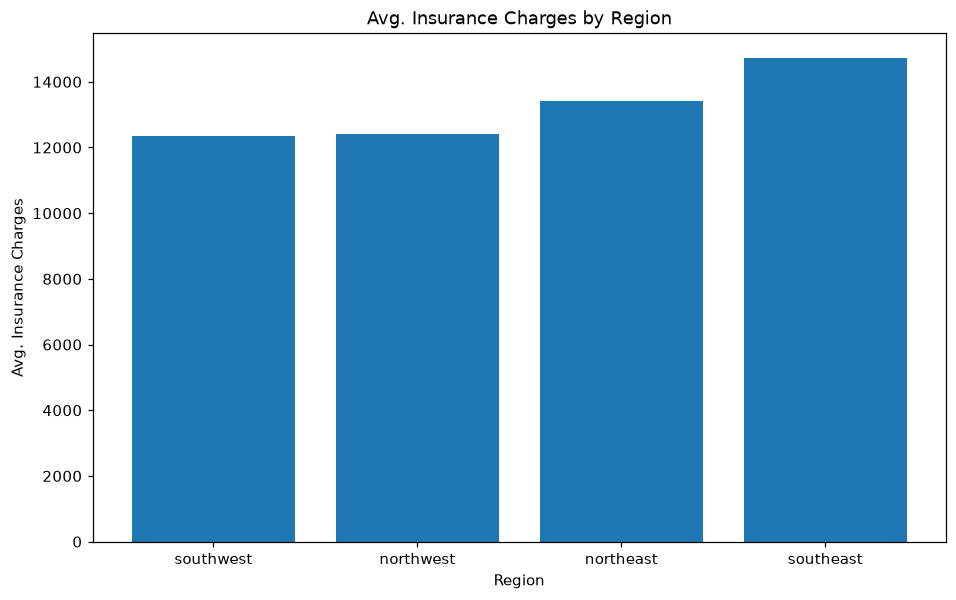

In [7]:
# 1

avg_charges = df.groupby('region')['charges'].mean().reset_index()
avg_charges = avg_charges.sort_values(by='charges')
display(avg_charges)

plt.figure(figsize=(10,6))
plt.bar(avg_charges['region'],avg_charges['charges'])
plt.xlabel('Region')
plt.ylabel('Avg. Insurance Charges')
plt.title("Avg. Insurance Charges by Region")
plt.show()

# The southeast region has the highest average insurance charges.

2. Using our linear `model`, create a column called `excess_charges` in `df` which represents the residual value of `charges`. Then create a bar chart of the average excess charges by region. Which region has the highest average excess insurance charges? What does this mean?

      region  excess_charges
2  southeast        -387.916
3  southwest        -361.488
1  northwest         222.342
0  northeast         575.382


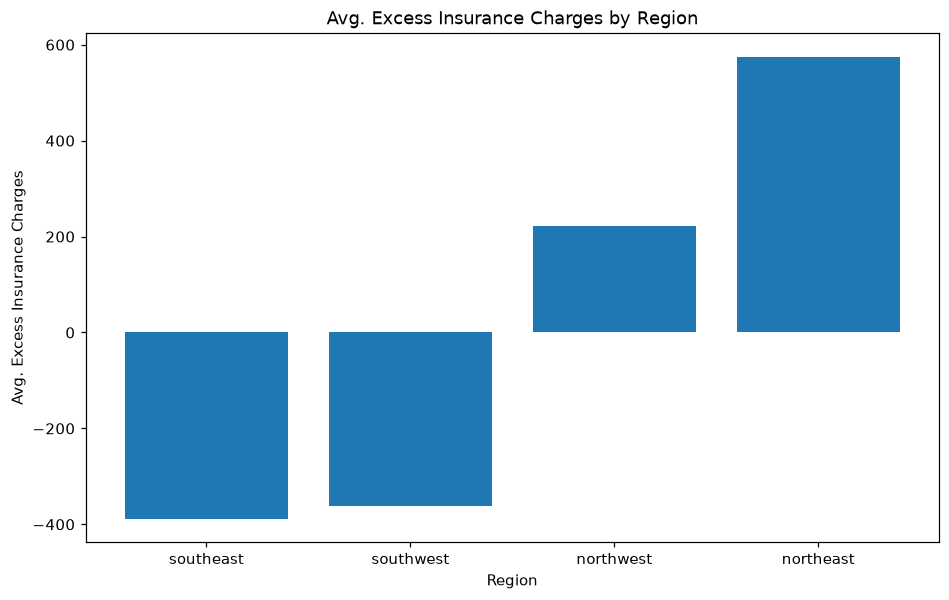

In [8]:
# 2

df['charges_hat'] = model.predict(X)
df['excess_charges'] = df['charges'] - df['charges_hat']

avg_excess_charges = df.groupby('region')['excess_charges'].mean().reset_index()
avg_excess_charges = avg_excess_charges.sort_values(by='excess_charges')
display(avg_excess_charges)

plt.figure(figsize=(10,6))
plt.bar(avg_excess_charges['region'],avg_excess_charges['excess_charges'])
plt.xlabel('Region')
plt.ylabel('Avg. Excess Insurance Charges')
plt.title("Avg. Excess Insurance Charges by Region")
plt.show()

# The northeast region has the highest excess insurance charges. This means that after controlling
# for factors like age, bmi, children, gender, and smoking, those in the northeast region tend to 
# have more charges than those in other regions. Perhaps these individuals demand more health care
# than those in other regions, something our model does not take into account.

#### Exercise 3

Run the cell below to read in the `insurance.csv` file we used in Exercise 1. You will use this data to create out-of-sample predictions for insurance charges.

In [9]:
df = pd.read_csv('insurance.csv')
df['male'] = np.where(df.sex == 'male', 1, 0)
df['smoke'] = np.where(df.smoker == 'yes', 1, 0)

1. Using `df`, create a training set called `train` containing a random subsample of 70% of the observations in `df`. Set the `random_state` in the `sample` function equal to `73723`. Create a test set called `test` containining the observations in `df` that are not in `train`.

In [10]:
# 1

# Create the training set

train = df.sample(frac=0.7, random_state=73723)

# All remaining rows go into the test set

test=df.drop(train.index)

2. Run a linear regression model using the `train` DataFrame with `charges` as the dependent variable and the following independent variables: `age`, `bmi`, `children`, `male`, and `smoke`.

In [11]:
# 2

X = train[['age','bmi','children','male','smoke']]
y = train['charges']

X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.733
Model:                            OLS   Adj. R-squared:                  0.731
Method:                 Least Squares   F-statistic:                     510.6
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          7.78e-264
Time:                        21:19:14   Log-Likelihood:                -9514.1
No. Observations:                 937   AIC:                         1.904e+04
Df Residuals:                     931   BIC:                         1.907e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -1.17e+04   1167.538    -10.017      0.0

3. Create a variable in the `test` DataFrame called `charges_hat` equal to the `charges` prediction obtained by applying the model created in the previous step to the observations in the `test` DataFrame.

In [12]:
# 3

X_test = test[['age','bmi','children','male','smoke']]
X_test = sm.add_constant(X_test)

test['charges_hat'] = model.predict(X_test)
test.head(10)

    age     sex    bmi  children smoker     region    charges  male  smoke  \
3    33    male 22.705         0     no  northwest 21,984.471     1      0   
6    46  female 33.440         1     no  southeast  8,240.590     0      0   
8    37    male 29.830         2     no  northeast  6,406.411     1      0   
11   62  female 26.290         0    yes  southeast 27,808.725     0      1   
12   23    male 34.400         0     no  southwest  1,826.843     1      0   
13   56  female 39.820         0     no  southeast 11,090.718     0      0   
21   30  female 32.400         1     no  southwest  4,149.736     0      0   
27   55  female 32.775         2     no  northwest 12,268.632     0      0   
30   22    male 35.600         0    yes  southwest 35,585.576     1      1   
33   63    male 28.310         0     no  northwest 13,770.098     1      0   

    charges_hat  
3     4,147.078  
6    10,869.375  
8     8,343.419  
11   35,791.366  
12    5,202.737  
13   14,906.843  
21    6,460.260

4. Evaluate the `charges_hat` prediction by estimating a simple linear regression with `charges` as the dependent variable and `charges_hat` as the independent variable in the `test` DataFrame. Comment on the model's ability to predict charges in the out-of-sample test set.

In [13]:
# 4

X = test[["charges_hat"]] 
y = test["charges"]
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

# The adjusted R-squared is equal to 0.786 which is pretty high suggesting that the model
# does a decent job of predicting charges in the out-of-sample data.

# The coefficient on charges_hat is equal to 1.0364 which is close to 1 suggesting that charges_hat
# is a close approximation of the actual charges.

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.787
Model:                            OLS   Adj. R-squared:                  0.786
Method:                 Least Squares   F-statistic:                     1471.
Date:                Thu, 15 Oct 2026   Prob (F-statistic):          6.58e-136
Time:                        21:19:14   Log-Likelihood:                -4035.1
No. Observations:                 401   AIC:                             8074.
Df Residuals:                     399   BIC:                             8082.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        -750.7727    471.362     -1.593      

5. Visually inspect the relationship between `charges` and `charges_hat` by creating a `matplotlib` scatter plot with `charges` on the y-axis and `charges_hat` on the x-axis.

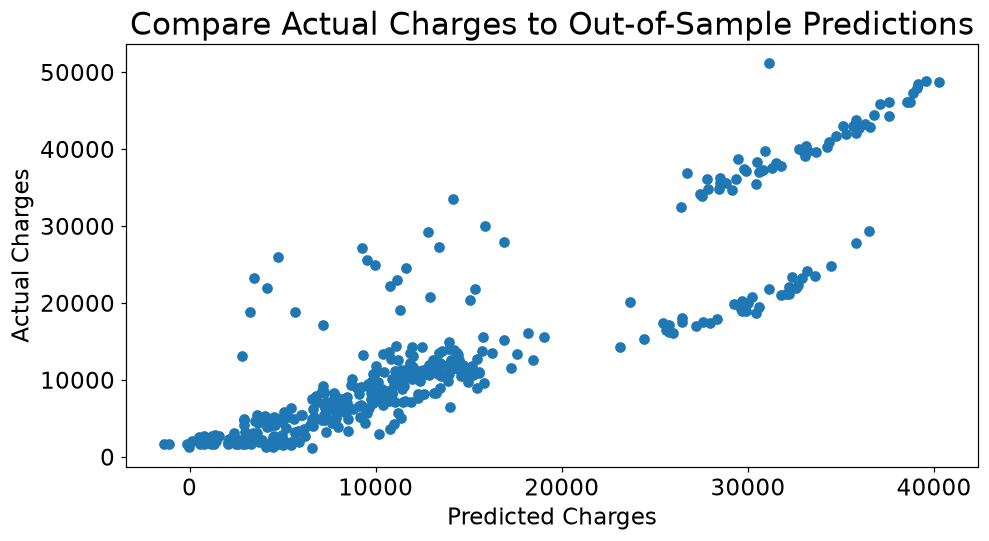

In [14]:
# 5

plt.figure(figsize=(10,5))
plt.scatter(test['charges_hat'],test['charges'])
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel('Predicted Charges',fontsize=15)
plt.ylabel('Actual Charges',fontsize=15)
plt.title('Compare Actual Charges to Out-of-Sample Predictions',fontsize=20)
plt.show()